# 5. Effet de l'industrie sur les nappes phréatiques

Objectif : déterminer si les nappes situées près des installations industrielles ont évolué plus défavorablement que les autres entre 2015 et 2025, **une fois l'effet de la pluie retiré** (partie 4).

Démarche :
1. Mesurer l'évolution de chaque nappe, climat retiré : la tendance corrigée de la partie 4.
2. Mesurer la pression industrielle autour de chaque station (nombre d'usines).
3. Comparer les deux, puis chercher ce qui distingue les stations (géologie, profondeur).
4. Vérifier avec les volumes d'eau réellement pompés (BNPE).

**Étape 5 sur 5.** Ce notebook exécute `eau_04_climat.ipynb` (qui exécute lui-même 03 puis 01), puis mesure l'effet de l'industrie sur la tendance des nappes une fois la pluie retirée.

Variables utilisées de la partie 4 : `tendances` (pentes brute et corrigée de chaque station) et `residu` (niveau mensuel sans la pluie).

Variables produites : `st`, `residu_annuel`, `ecart_annuel`, `usines`, `prelevements`, `sout`, `focus`, `tableau_corr`.

**Organisation des notebooks.**

| Notebook | Contenu | Exécute d'abord |
|---|---|---|
| `eau_01_donnees.ipynb` | Récupération et préparation des données | — |
| `eau_02_usines_stations.ipynb` | Usines et stations : premier regard | 01 |
| `eau_03_geographie.ipynb` | Altitude, roche, profondeur | 01 |
| `eau_04_climat.ipynb` | Retrait de l'effet de la pluie | 03 |
| `eau_05_industrie.ipynb` | Effet de l'industrie, climat retiré | 04 |
| `rapport.ipynb` | Figures et interprétations uniquement | 02, 04, 05 |

Chaque notebook exécute ceux dont il a besoin avec `%run`, sans afficher leurs sorties et une seule fois par noyau : pour tout recalculer après une modification, redémarrer le noyau.

In [1]:
%%capture
#Étapes précédentes : exécutées sans afficher leurs figures ni leurs messages, et une seule fois par noyau
#(si les données ne sont pas encore en cache, exécuter d'abord eau_01_donnees.ipynb seul pour suivre le téléchargement)
AFFICHER = globals().get("AFFICHER", True)   #True si ce notebook est ouvert seul, False s'il est appelé par un autre notebook
_afficher_etape_05, AFFICHER = AFFICHER, False
if "ETAPE_04" not in globals():
    %run ./meteo_pluie.ipynb
AFFICHER = _afficher_etape_05
plt.close("all")

## 5.1 Mesure de l'évolution des nappes, climat retiré

Pour chaque station, l'évolution est la **tendance corrigée du climat** calculée en partie 4 : la pente de Sen saisonnière du résidu (niveau observé moins la partie expliquée par la pluie et les saisons), en cm/an.

Cet indicateur a deux avantages sur une simple comparaison entre le début et la fin de la période : il utilise toute la série, donc ne dépend pas du choix des périodes, et la pluie étant retirée, une année exceptionnellement humide comme 2024 ne le fausse plus.
On étudie donc les stations bien suivies de la partie 4 (au moins 80 % des mois mesurés). Pour comparer, on garde aussi la pente brute, calculée de la même façon avant le retrait du climat.

In [2]:
# On crée le tableau de travail : les stations de la partie 4 avec leur tendance, leur profondeur et leur géologie
st = stations.merge(tendances[["pente_brute_cm_an", "pente_corrigee_cm_an"]].reset_index(), on="code_bss")
st["tendance_cm_an"] = st["pente_corrigee_cm_an"]   #Indicateur d'évolution de toute la partie : la tendance une fois la pluie retirée

st["profondeur_investigation"] = pd.to_numeric(st["profondeur_investigation"], errors="coerce")
st["classe_profondeur"] = pd.cut(st["profondeur_investigation"], bins=[-np.inf, 30, 80, np.inf], labels=["Superficielle (<30m)", "Intermédiaire (30-80m)", "Profonde (>80m)"])

noms = st["noms_masse_eau_edl"].astype(str)
st["famille_geologique"] = np.select(
    [noms.str.contains("Craie", case=False), noms.str.contains("Sable|Landénien", case=False), noms.str.contains("Calcaire", case=False)],
    ["Craie", "Sable", "Calcaire"],
    default="Autre"
)

print("Stations étudiées :", len(st))
print(st["tendance_cm_an"].describe().round(2))

Stations étudiées : 45
count    45.00
mean     -8.70
std      10.90
min     -57.12
25%     -11.79
50%      -4.60
75%      -1.93
max       3.77
Name: tendance_cm_an, dtype: float64


In [3]:
#Trajectoire annuelle de chaque station sans la pluie : moyenne annuelle du résidu de la partie 4 (années d'au moins 10 mois mesurés),
#en écart à sa moyenne 2015-2017 (on travaille sur des moyennes annuelles pour ne jamais comparer un été à un hiver)
mois_mesures = residu.notna().groupby(residu.index.year).sum()
residu_annuel = residu.groupby(residu.index.year).mean().where(mois_mesures >= 10)   #Une ligne par année, une colonne par station
ecart_annuel = residu_annuel - residu_annuel.loc[2015:2017].mean()

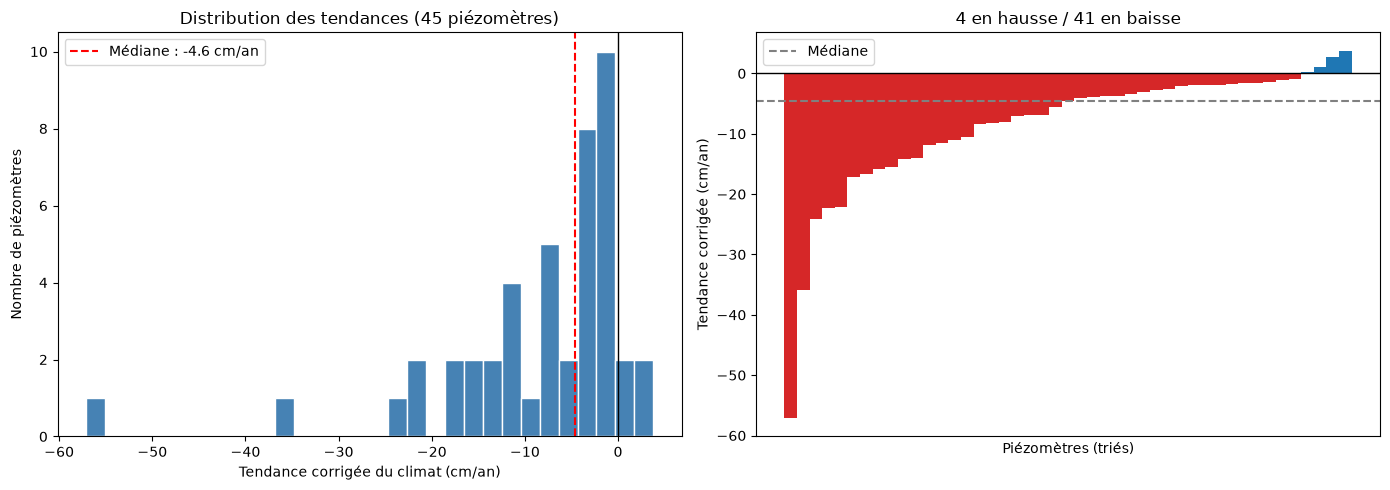

In [4]:
def fig_distribution_evolutions():
    """Histogramme et classement des tendances corrigées du climat de chaque piézomètre."""
    med = st["tendance_cm_an"].median()
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    axes[0].hist(st["tendance_cm_an"], bins=30, color="steelblue", edgecolor="white")
    axes[0].axvline(0, color="black", linewidth=1)
    axes[0].axvline(med, color="red", linestyle="--", label=f"Médiane : {med:+.1f} cm/an")
    axes[0].set_xlabel("Tendance corrigée du climat (cm/an)")
    axes[0].set_ylabel("Nombre de piézomètres")
    axes[0].set_title(f"Distribution des tendances ({len(st)} piézomètres)")
    axes[0].legend()

    tri = st["tendance_cm_an"].sort_values().reset_index(drop=True)
    axes[1].bar(tri.index, tri, width=1, color=np.where(tri < 0, "tab:red", "tab:blue"))
    axes[1].axhline(0, color="black", linewidth=1)
    axes[1].axhline(med, color="grey", linestyle="--", label="Médiane")
    axes[1].set_xticks([])
    axes[1].set_xlabel("Piézomètres (triés)")
    axes[1].set_ylabel("Tendance corrigée (cm/an)")
    axes[1].set_title(f"{(tri > 0).sum()} en hausse / {(tri < 0).sum()} en baisse")
    axes[1].legend()

    plt.tight_layout()
    plt.show()

if AFFICHER:
    fig_distribution_evolutions()

**Interprétation.** Une fois la pluie retirée, 41 des 45 stations sont en baisse, avec une médiane de −4,6 cm/an : à pluie égale, la nappe typique du Nord baisse légèrement. La moitié des stations ont une tendance comprise entre −11,8 et −1,9 cm/an, et les 4 stations en hausse le sont de moins de 4 cm/an. Dans les niveaux bruts, ce mouvement est masqué par les années humides de la fin de période (voir partie 4).

Les plus fortes baisses sont Bondues (−57 cm/an), Nieppe (−36 cm/an) et Quesnoy-sur-Deûle (−24 cm/an) : trois nappes captives, pour lesquelles le modèle, qui suppose une recharge par la pluie locale, est à lire avec prudence.

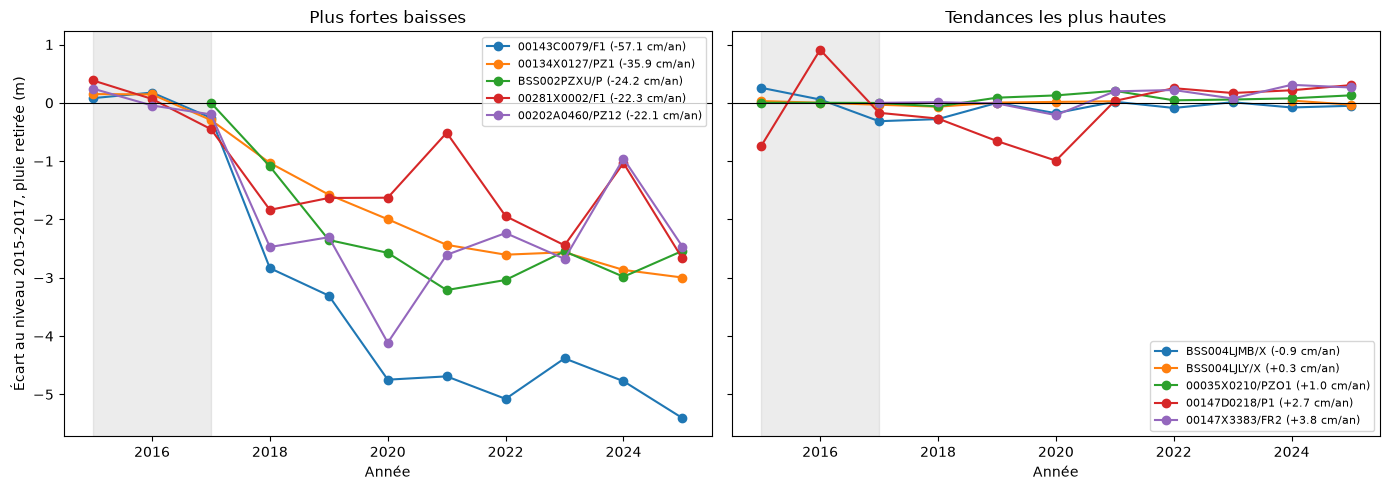

In [5]:
def fig_plus_fortes_evolutions():
    """Trajectoire annuelle, climat retiré, des 5 plus fortes baisses et des 5 tendances les plus hautes."""
    tri_st = st.sort_values("tendance_cm_an")
    fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
    for ax, codes, titre in [(axes[0], tri_st["code_bss"].head(5), "Plus fortes baisses"), (axes[1], tri_st["code_bss"].tail(5), "Tendances les plus hautes")]:
        for code in codes:
            tendance = st.loc[st["code_bss"] == code, "tendance_cm_an"].iloc[0]
            ax.plot(ecart_annuel.index, ecart_annuel[code], marker="o", label=f"{code} ({tendance:+.1f} cm/an)")
        ax.axvspan(2015, 2017, color="grey", alpha=0.15)   #Période de référence
        ax.axhline(0, color="black", linewidth=0.8)
        ax.set_title(titre)
        ax.set_xlabel("Année")
        ax.legend(fontsize=8)
    axes[0].set_ylabel("Écart au niveau 2015-2017, pluie retirée (m)")
    plt.tight_layout()
    plt.show()

if AFFICHER:
    fig_plus_fortes_evolutions()

**Interprétation.** À gauche, les plus fortes baisses ne sont pas régulières : l'essentiel de la chute se produit entre 2017 et 2020, puis le niveau reste bas. Bondues perd ainsi près de 5 m entre 2017 et 2020 et ne remonte pas ensuite (−5,4 m en 2025). Nieppe est la seule à baisser de façon régulière, d'environ 1 m en 2018 à 3 m en 2025. Rieulay (00281X0002/F1) et Gondecourt (00202A0460/PZ12) ont des remontées ponctuelles, en 2021 et en 2024, que le modèle n'a pas absorbées : pour ces stations, une part de l'effet de la pluie reste probablement dans le résidu.

La chute de 2017-2020 coïncide avec des années sèches. Ces données ne permettent pas de trancher entre deux lectures : le modèle sous-estime l'effet d'une sécheresse longue sur ces nappes, ou un facteur non climatique s'est ajouté pendant ces années.

À droite, les stations aux tendances les plus hautes restent à moins de 1 m de leur niveau de 2015-2017 : une fois la pluie retirée, aucune nappe ne monte nettement.

## 5.2 Premier indicateur de pression : le nombre d'usines

On ne garde que l'industrie manufacturière (codes NAF 10 à 33) et l'énergie (code 35), qui sont les activités les plus consommatrices d'eau. Pour chaque station, on compte les usines situées à moins de 2, 5 et 10 km, afin de vérifier que le résultat ne dépend pas du rayon choisi.

Les stations sont ensuite réparties en trois groupes : 0 usine, 1 à 5 usines, plus de 5 usines (dans un rayon de 5 km).

In [6]:
# On ne garde que l'industrie manufacturière et l'énergie
code_naf = pd.to_numeric(installations_indust["code_naf"].astype(str).str[:2], errors="coerce")
usines = installations_indust[code_naf.between(10, 33) | (code_naf == 35)]
print("Usines manufacturières et énergétiques retenues :", len(usines))

#On compte les usines à proximité de chaque station avec différents rayons
for rayon_km in [2, 5, 10]:
    st[f"usines_{rayon_km}km"] = st.geometry.apply(lambda g: (usines.distance(g) <= rayon_km * 1000).sum())

#On sépare les stations en fonction de la pression industrielle (=nb d'usines aux alentours) qu'elles subissent
st["pression"] = pd.cut(st["usines_5km"], bins=[-1, 0, 5, 10000], labels=["0 usine", "1 à 5 usines", "plus de 5 usines"])
print(st["pression"].value_counts())

Usines manufacturières et énergétiques retenues : 428
pression
plus de 5 usines    21
1 à 5 usines        19
0 usine              5
Name: count, dtype: int64


                  count   mean    std    min    25%   50%   75%   max
pression                                                             
0 usine             5.0  -7.63   7.97 -17.19 -15.48 -2.00 -1.87 -1.61
1 à 5 usines       19.0  -7.35   6.46 -22.27 -12.76 -4.03 -2.67  0.29
plus de 5 usines   21.0 -10.17  14.37 -57.12 -11.08 -6.88 -1.93  3.77


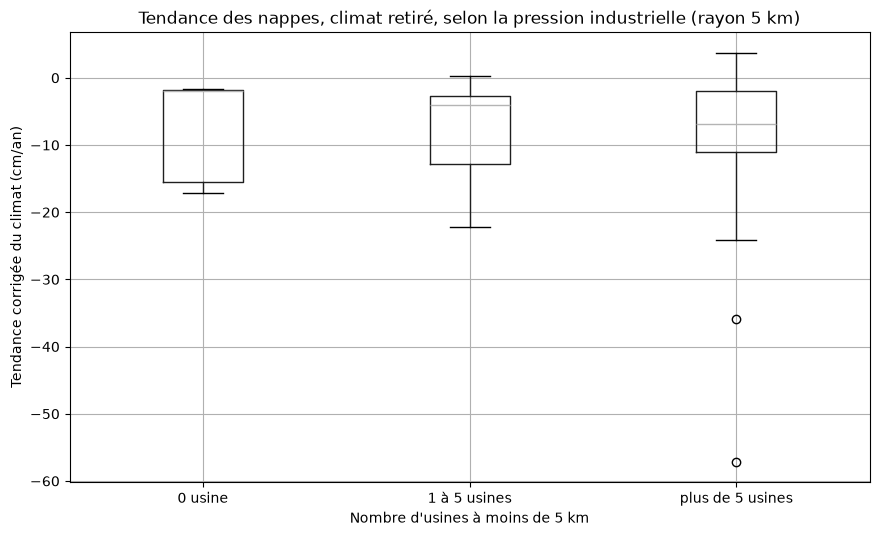

In [7]:
evolution_par_pression = st.groupby("pression", observed=False)["tendance_cm_an"].describe().round(2)
print(evolution_par_pression)

def fig_evolution_par_pression_boxplot():
    """Boîtes à moustaches de la tendance corrigée selon le nombre d'usines à moins de 5 km."""
    st.boxplot(column="tendance_cm_an", by="pression", figsize=(10, 6))
    plt.suptitle("")
    plt.title("Tendance des nappes, climat retiré, selon la pression industrielle (rayon 5 km)")
    plt.xlabel("Nombre d'usines à moins de 5 km")
    plt.ylabel("Tendance corrigée du climat (cm/an)")
    plt.show()

if AFFICHER:
    fig_evolution_par_pression_boxplot()

**Interprétation.** Les médianes semblent baisser avec le nombre d'usines : −2,0 cm/an sans usine, −4,0 cm/an pour 1 à 5 usines et −6,9 cm/an pour plus de 5 usines. Ce gradient est pourtant fragile.

Le groupe « 0 usine » ne compte que 5 stations, et sa médiane cache une forte dispersion : son premier quartile (−15,5 cm/an) est le plus bas des trois groupes. Entre « 1 à 5 » et « plus de 5 usines », les boîtes se recouvrent presque entièrement : la moitié centrale des stations va de −12,8 à −2,7 cm/an dans le premier groupe, de −11,1 à −1,9 cm/an dans le second.

La moyenne du groupe le plus industriel (−10,2 cm/an) est tirée vers le bas par Bondues (−57 cm/an), qui gonfle aussi son écart-type (14,4 cm/an contre 6 à 8 dans les autres groupes).

In [8]:
for rayon_km in [2, 5, 10]:
    print(f"Spearman tendance corrigée / usines à {rayon_km} km :", round(st["tendance_cm_an"].corr(st[f"usines_{rayon_km}km"], method="spearman"), 2))

Spearman tendance corrigée / usines à 2 km : 0.13
Spearman tendance corrigée / usines à 5 km : 0.01
Spearman tendance corrigée / usines à 10 km : 0.1


On utilise la corrélation de Spearman : elle mesure si « plus d'usines » va avec « plus de baisse ». Une corrélation **négative** indiquerait que les nappes entourées de plus d'usines baissent davantage.

**Interprétation.** Elle vaut 0,13 à 2 km, 0,01 à 5 km et 0,10 à 10 km : des valeurs proches de zéro et jamais négatives. Quand on classe les stations de la plus exposée à la moins exposée, elles ne baissent pas davantage avec le nombre d'usines, quel que soit le rayon. L'écart entre les médianes des groupes ne se retrouve donc pas dans ce classement : il tient surtout aux petits effectifs.

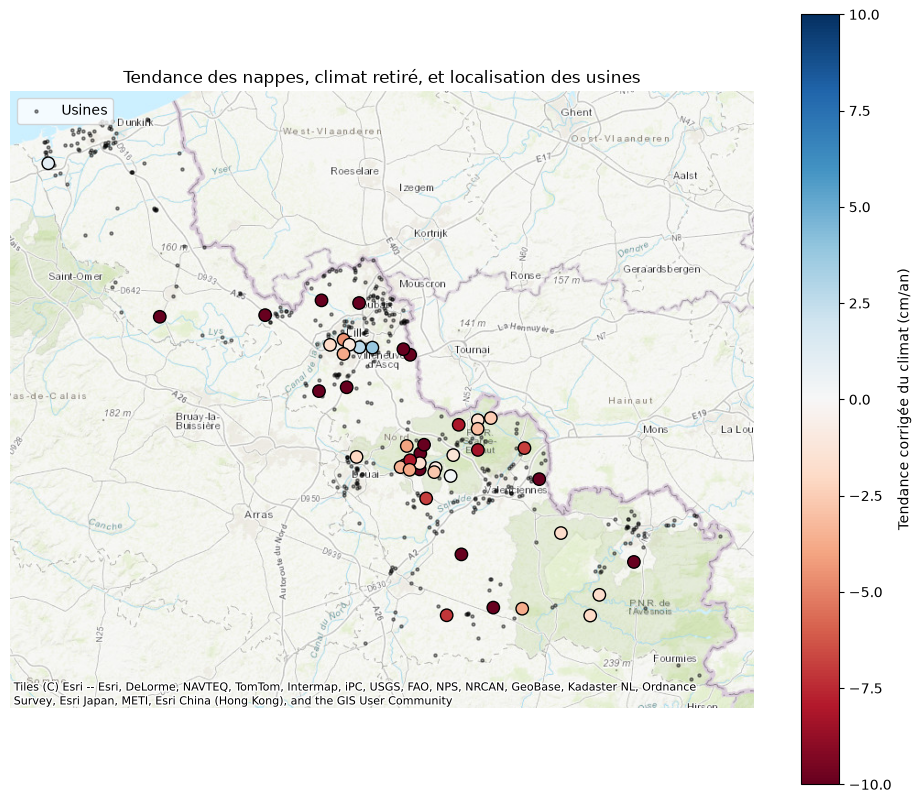

In [9]:
def fig_carte_evolutions():
    """Carte des stations colorées selon leur tendance corrigée du climat, avec les usines en noir."""
    fig, ax = plt.subplots(figsize=(12, 10))
    usines.to_crs(epsg=3857).plot(ax=ax, color="black", markersize=5, alpha=0.4, label="Usines", zorder=2)
    st.to_crs(epsg=3857).plot(ax=ax, column="tendance_cm_an", cmap="RdBu", norm=TwoSlopeNorm(vmin=-10, vcenter=0, vmax=10), markersize=80, edgecolor="black", legend=True, legend_kwds={"label": "Tendance corrigée du climat (cm/an)"}, zorder=3)
    ctx.add_basemap(ax, source=ctx.providers.Esri.WorldTopoMap, zorder=1)
    ax.set_axis_off()
    plt.legend(loc="upper left")
    plt.title("Tendance des nappes, climat retiré, et localisation des usines")
    plt.show()

if AFFICHER:
    fig_carte_evolutions()

La couleur sature à ±10 cm/an pour que les petites tendances restent visibles.

**Interprétation.** Les fortes baisses (rouge foncé) sont dispersées dans tout le département : en Flandre intérieure (Nieppe), au nord et au sud de Lille, dans la plaine de la Scarpe, dans le Cambrésis et dans l'Avesnois. Elles ne se concentrent pas autour des pôles industriels : au cœur de la métropole lilloise, où les usines sont les plus denses, les stations sont presque stables (couleurs pâles ou bleues), comme la station du littoral près de Dunkerque.

## 5.3 Ce qui distingue les stations en baisse

On regarde les caractéristiques des stations extrêmes, puis l'effet de la géologie et de la profondeur, pour voir si elles expliquent mieux les différences entre stations que la pression industrielle.

In [10]:
colonnes = ["code_bss", "nom_commune", "tendance_cm_an", "usines_5km", "classe_profondeur", "famille_geologique"]
stations_extremes = pd.concat([st.sort_values("tendance_cm_an")[colonnes].head(8), st.sort_values("tendance_cm_an")[colonnes].tail(5)])
print("Plus fortes baisses")
print(st.sort_values("tendance_cm_an")[colonnes].head(8).to_string(index=False))
print("\nTendances les plus hautes")
print(st.sort_values("tendance_cm_an")[colonnes].tail(5).to_string(index=False))

Plus fortes baisses
        code_bss         nom_commune  tendance_cm_an  usines_5km      classe_profondeur famille_geologique
   00143C0079/F1             Bondues      -57.116177          21        Profonde (>80m)           Calcaire
  00134X0127/PZ1              Nieppe      -35.850084          11 Intermédiaire (30-80m)              Sable
    BSS002PZXU/P   Quesnoy-sur-Deûle      -24.197009           6        Profonde (>80m)           Calcaire
   00281X0002/F1             Rieulay      -22.271332           1 Intermédiaire (30-80m)              Craie
 00202A0460/PZ12          Gondecourt      -22.079086          10   Superficielle (<30m)              Craie
00286X0405/PZST2 Villers-en-Cauchies      -17.191634           0   Superficielle (<30m)              Craie
  00384X0296/PZ4     Limont-Fontaine      -16.620184           4        Profonde (>80m)           Calcaire
    BSS004LJKU/X     Beuvry-la-Forêt      -15.809219           5   Superficielle (<30m)              Autre

Tendances les pl

**Interprétation.** Les plus fortes baisses ne sont pas toutes entourées d'usines : Bondues (21 usines) et Nieppe (11) le sont, mais Rieulay n'en a qu'une, Villers-en-Cauchies aucune et Limont-Fontaine 4. À l'inverse, les deux tendances les plus hautes sont celles de Lille (00147D0218/P1, 22 usines, +2,7 cm/an) et de Villeneuve-d'Ascq (20 usines, +3,8 cm/an).

Bondues et ces deux stations ont presque le même nombre d'usines, mais des tendances opposées. Ce qui les distingue est le type de nappe : Bondues est un forage profond dans le calcaire, Lille et Villeneuve-d'Ascq des piézomètres superficiels dans la craie. Les cinq tendances les plus hautes sont toutes des nappes superficielles, alors que les huit plus fortes baisses comptent trois ouvrages profonds et deux intermédiaires.

Limont-Fontaine avait la plus forte pente brute du département (+57,6 cm/an) ; une fois la pluie retirée, elle passe à −16,6 cm/an. Sa hausse apparente venait de la pluie, mais ses données restent atypiques et à interpréter avec prudence.

classe_profondeur   Superficielle (<30m)  Intermédiaire (30-80m)  \
famille_geologique                                                 
Autre                                 14                       0   
Calcaire                               0                       1   
Craie                                 10                       9   
Sable                                  3                       1   
All                                   27                      11   

classe_profondeur   Profonde (>80m)  All  
famille_geologique                        
Autre                             0   14  
Calcaire                          6    7  
Craie                             0   19  
Sable                             1    5  
All                               7   45  
                    count   mean    std    min    25%    50%   75%   max
famille_geologique                                                      
Autre                14.0  -4.31   4.17 -15.81  -5.22  -3.26 -1.62  0.29
Cal

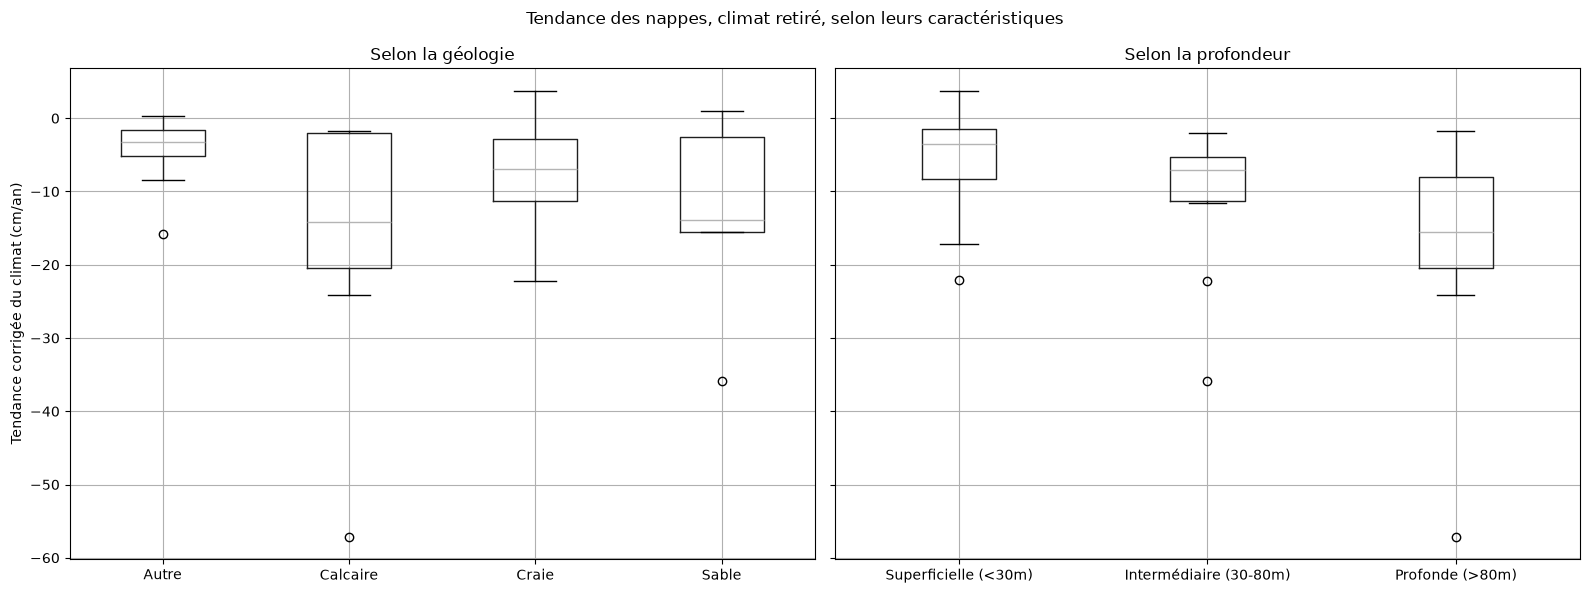

In [11]:
print(pd.crosstab(st["famille_geologique"], st["classe_profondeur"], margins=True))
print(st.groupby("famille_geologique")["tendance_cm_an"].describe().round(2))
print(st.groupby("classe_profondeur", observed=False)["tendance_cm_an"].describe().round(2))

def fig_evolution_geologie_profondeur():
    """Boîtes à moustaches de la tendance corrigée selon la géologie et selon la profondeur."""
    fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharey=True)
    st.boxplot(column="tendance_cm_an", by="famille_geologique", ax=axes[0])
    st.boxplot(column="tendance_cm_an", by="classe_profondeur", ax=axes[1])
    axes[0].set_title("Selon la géologie")
    axes[1].set_title("Selon la profondeur")
    axes[0].set_xlabel("")
    axes[1].set_xlabel("")
    axes[0].set_ylabel("Tendance corrigée du climat (cm/an)")
    plt.suptitle("Tendance des nappes, climat retiré, selon leurs caractéristiques")
    plt.tight_layout()
    plt.show()

if AFFICHER:
    fig_evolution_geologie_profondeur()

**Interprétation : la géologie.** Les médianes vont de −3,3 cm/an à −14,2 cm/an selon la géologie, soit un écart d'environ 11 cm/an : plus du double de l'écart entre les groupes de pression industrielle (environ 5 cm/an).

- **Craie** (19 stations) : médiane −6,9 cm/an.
- **Calcaire** (7 stations) : médiane −14,2 cm/an, avec la plus forte baisse du département (Bondues).
- **Sable** (5 stations) : médiane −13,9 cm/an, dont Nieppe. Résultat fragile vu le faible effectif.
- **Autre** (14 stations, piézomètres superficiels sans masse d'eau renseignée) : médiane −3,3 cm/an, les plus stables.

**Interprétation : la profondeur.** Le gradient est net : médiane de −3,5 cm/an pour les ouvrages superficiels (27 stations), −7,1 cm/an pour les intermédiaires (11) et −15,5 cm/an pour les profonds (7). La dispersion augmente aussi avec la profondeur (écart-type de 6,3 cm/an en surface contre 18,7 cm/an en profondeur). Une fois la pluie retirée, ce sont donc les nappes profondes qui baissent le plus : la profondeur différencie davantage les stations que le nombre d'usines.

**Attention :** 6 des 7 ouvrages profonds sont aussi calcaires, et le septième est sableux : on ne peut pas séparer l'effet de la profondeur de celui de la géologie. Deux d'entre eux (Bondues, Quesnoy-sur-Deûle) captent des nappes captives, pour lesquelles le modèle climat est à lire avec prudence.

## 5.4 Deuxième indicateur de pression : les volumes pompés

Le nombre d'usines est un indicateur imparfait : une petite usine et une grande usine comptent pareil, et une usine ne pompe pas forcément dans la nappe. Pour vérifier que l'absence de lien ne vient pas de ce choix d'indicateur, on utilise les volumes réellement prélevés.

La BNPE (Banque Nationale des Prélèvements quantitatifs en Eau) recense, pour chaque ouvrage (forage, puits, prise d'eau) et chaque année, le volume prélevé et son usage.

In [12]:
# On télécharge les données sur les prélèvements (un fichier en cache par département)
url_bnpe = "https://hubeau.eaufrance.fr/api/v1/prelevements/chroniques"

def telecharger_toutes_pages(url, params_api):
    """Récupère toutes les pages d'une réponse Hub'eau en suivant le lien "next" (requete_hubeau réessaie en cas de coupure)."""
    lignes_api = []
    while url is not None:
        data = requete_hubeau(params_api, url)
        lignes_api.extend(data["data"])
        url = data.get("next")
        params_api = None   #Les paramètres sont déjà intégrés dans l'url de la page "next"
        time.sleep(0.5)     #On attend un peu pour éviter de se faire rejeter par le serveur
    return lignes_api

morceaux = []
for dep in DEPARTEMENTS:
    chemin_bnpe = f"../../data/prelevements_{dep}.csv"
    if not os.path.exists(chemin_bnpe):
        prelevements_dep = []
        #Comme pour le téléchargement des chroniques, les données de prélèvement sont trop lourdes à télécharger d'un seul coup : on les télécharge année après année.
        for annee in range(2015, 2026):
            prelevements_dep.extend(telecharger_toutes_pages(url_bnpe, {"code_departement": dep, "annee": annee, "size": 2000, "format": "json"}))
            print(f"Département {dep}, année {annee} terminée")
        pd.DataFrame(prelevements_dep).to_csv(chemin_bnpe, index=False, encoding="utf-8")
        print("Téléchargement réussi.")
    morceaux.append(pd.read_csv(chemin_bnpe, encoding="utf-8"))
prelevements = pd.concat(morceaux, ignore_index=True)

In [13]:
url_ouvrages = "https://hubeau.eaufrance.fr/api/v1/prelevements/referentiel/ouvrages"

morceaux = []
for dep in DEPARTEMENTS:
    chemin_ouvrages = f"../../data/ouvrages_{dep}.csv"
    if not os.path.exists(chemin_ouvrages):
        pd.DataFrame(telecharger_toutes_pages(url_ouvrages, {"code_departement": dep, "size": 5000, "format": "json"})).to_csv(chemin_ouvrages, index=False, encoding="utf-8")
    morceaux.append(pd.read_csv(chemin_ouvrages, encoding="utf-8"))
ouvrages = pd.concat(morceaux, ignore_index=True).drop_duplicates(subset="code_ouvrage")

prelevements = prelevements.merge(ouvrages[["code_ouvrage", "libelle_type_milieu"]], on="code_ouvrage", how="left")
sout = prelevements[prelevements["libelle_type_milieu"].str.contains("souterrain", case=False, na=False)]
sout = gpd.GeoDataFrame(sout.drop(columns="geometry"), geometry=gpd.points_from_xy(sout["longitude"], sout["latitude"]), crs="EPSG:4326").to_crs(epsg=2154)

print(ouvrages["libelle_type_milieu"].value_counts())
print(len(prelevements), "prélèvements, dont", len(sout), "souterrains")

libelle_type_milieu
Souterrain             690
Surface continental     86
Name: count, dtype: int64
4811 prélèvements, dont 4309 souterrains


**Qualité des données.** Le nombre de prélèvements est stable d'une année à l'autre (500 à 614) : les données ne semblent pas tronquées. Elles s'arrêtent en 2023, en raison du délai de déclaration. Sur 776 ouvrages, 690 puisent dans une nappe et 86 en surface. On ne garde que les prélèvements souterrains, les seuls susceptibles de faire baisser une nappe.

code_usage
Eau potable    1069.8
Industrie       244.7
Irrigation       30.5
Name: volume, dtype: float64
code_usage
Eau potable    79.5
Industrie      18.2
Irrigation      2.3
Name: volume, dtype: float64


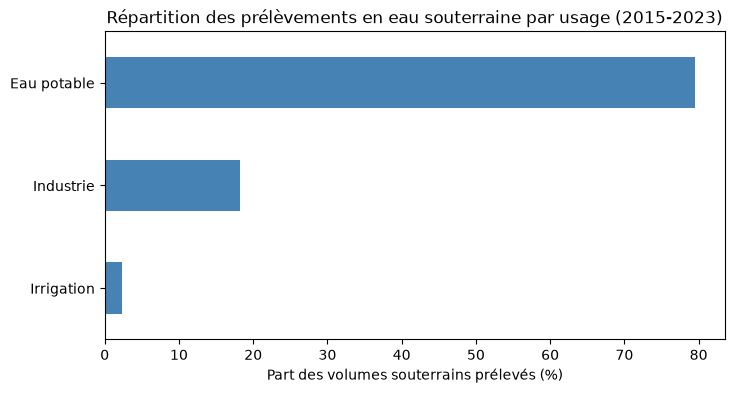

In [14]:
# Répartition de l'usage de l'eau pompée
noms_usages = {"AEP": "Eau potable", "IND": "Industrie", "IRR": "Irrigation"}
part = sout.groupby("code_usage")["volume"].sum().rename(index=noms_usages)
print((part / 1e6).round(1).sort_values(ascending=False))
print((100 * part / part.sum()).round(1).sort_values(ascending=False))

def fig_part_usages():
    """Part de chaque usage dans les volumes souterrains prélevés."""
    (100 * part / part.sum()).sort_values().plot(kind="barh", figsize=(8, 4), color="steelblue")
    plt.xlabel("Part des volumes souterrains prélevés (%)")
    plt.ylabel("")
    plt.title("Répartition des prélèvements en eau souterraine par usage (2015-2023)")
    plt.show()

if AFFICHER:
    fig_part_usages()

             2015-2017  2021-2023  évolution (%)
code_usage                                      
Eau potable      122.4      112.9           -7.8
Industrie         27.0       27.7            2.6
Irrigation         2.0        4.2          109.0


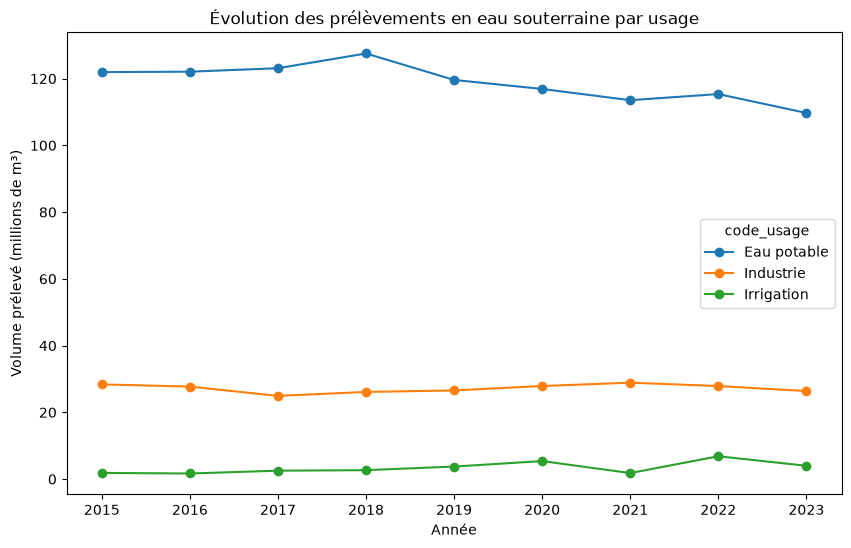

In [15]:
# Évolution des prélèvements
par_an = sout.pivot_table(values="volume", index="annee", columns="code_usage", aggfunc="sum").rename(columns=noms_usages) / 1e6

comparaison = pd.DataFrame({"2015-2017": par_an.loc[2015:2017].mean(), "2021-2023": par_an.loc[2021:2023].mean()})
comparaison["évolution (%)"] = 100 * (comparaison["2021-2023"] / comparaison["2015-2017"] - 1)
print(comparaison.round(1))

def fig_prelevements_par_an():
    """Volumes souterrains prélevés chaque année, par usage."""
    par_an.plot(figsize=(10, 6), marker="o")
    plt.ylabel("Volume prélevé (millions de m³)")
    plt.xlabel("Année")
    plt.title("Évolution des prélèvements en eau souterraine par usage")
    plt.show()

if AFFICHER:
    fig_prelevements_par_an()

**Interprétation.** L'eau potable domine très largement les prélèvements en eau souterraine : 79,5 % des volumes entre 2015 et 2023, contre 18,2 % pour l'industrie et 2,3 % pour l'irrigation.

- **Eau potable** : environ 110 à 128 millions de m³ par an, en baisse d'environ 8 % entre 2015-2017 et 2021-2023.
- **Industrie** : stable autour de 25 à 29 millions de m³ par an (+3 % entre les deux périodes).
- **Irrigation** : volumes très faibles (2 à 7 millions de m³), plus élevés les années sèches (2020 et 2022).

L'industrie pompe donc peu dans les nappes du Nord, et de façon stable : il est cohérent que la présence d'usines ne se voie pas dans l'évolution des nappes. La corrélation légèrement positive ne s'explique pas non plus par une baisse des pompages industriels, puisque ceux-ci n'ont pas diminué.

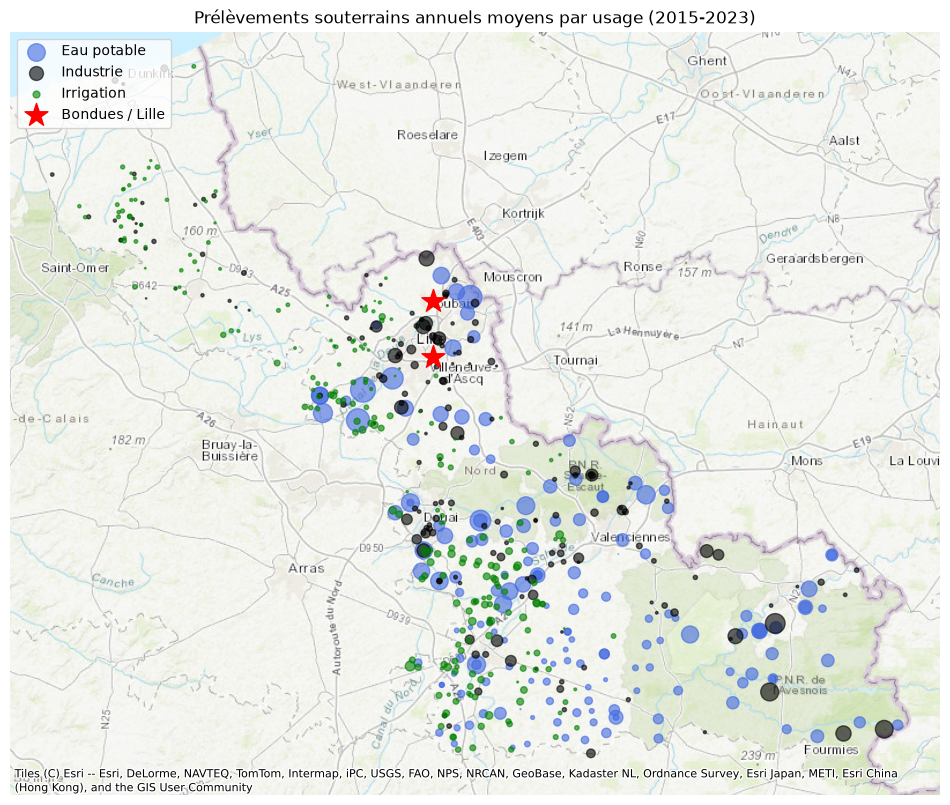

In [16]:
# Volume annuel moyen de chaque ouvrage souterrain, par usage
ouv = sout.groupby(["code_ouvrage", "code_usage"]).agg(volume=("volume", "mean"), geometry=("geometry", "first")).reset_index()
ouv = gpd.GeoDataFrame(ouv, geometry="geometry", crs=sout.crs).to_crs(epsg=3857)

def fig_carte_prelevements():
    """Carte des prélèvements souterrains, taille proportionnelle au volume annuel moyen."""
    couleurs = {"AEP": "royalblue", "IND": "black", "IRR": "green"}
    fig, ax = plt.subplots(figsize=(12, 10))
    for code, couleur in couleurs.items():
        sel = ouv[ouv["code_usage"] == code]
        sel.plot(ax=ax, color=couleur, markersize=np.sqrt(sel["volume"]) / 10, alpha=0.6, label=noms_usages[code], zorder=2)
    st[st["code_bss"].isin(["00143C0079/F1", "00147D0218/P1"])].to_crs(epsg=3857).plot(ax=ax, color="red", marker="*", markersize=300, label="Bondues / Lille", zorder=3)
    ctx.add_basemap(ax, source=ctx.providers.Esri.WorldTopoMap, zorder=1)
    ax.set_axis_off()
    plt.legend(loc="upper left")
    plt.title("Prélèvements souterrains annuels moyens par usage (2015-2023)")
    plt.show()

if AFFICHER:
    fig_carte_prelevements()

**Interprétation.** La taille des cercles est proportionnelle au volume annuel moyen prélevé. Les prélèvements pour l'eau potable (bleu) sont les plus importants et se concentrent autour de la métropole lilloise, de Douai-Valenciennes et de l'Avesnois. Les prélèvements industriels (noir) sont dispersés et généralement plus petits. L'irrigation (vert) correspond à de nombreux petits prélèvements en Flandre intérieure et dans le Cambrésis.

In [17]:
# Concentrons-nous sur les prélèvements autour des stations clés (stations du Nord : ignorées si elles ne font pas partie des départements étudiés)
codes_focus = ["00143C0079/F1", "00134X0127/PZ1", "00146B0007/F1", "00146X2045/PZF", "00146B0737/PZR2", "00147X3381/PZ6", "00147D0218/P1"]
lignes = []
for _, s in st[st["code_bss"].isin(codes_focus)].iterrows():
    proches = sout[sout.distance(s.geometry) <= 5000]
    nb_annees = max(proches["annee"].nunique(), 1)
    vol = proches.groupby("code_usage")["volume"].sum() / nb_annees / 1e6
    lignes.append({
        "code_bss": s["code_bss"],
        "commune": s["nom_commune"],
        "profondeur": s["classe_profondeur"],
        "geologie": s["famille_geologique"],
        "tendance_cm_an": round(s["tendance_cm_an"], 2),
        "eau_potable": round(vol.get("AEP", 0), 2),
        "industrie": round(vol.get("IND", 0), 2),
        "total": round(vol.sum(), 2)
    })
focus = pd.DataFrame(lignes, columns=["code_bss", "commune", "profondeur", "geologie", "tendance_cm_an", "eau_potable", "industrie", "total"]).sort_values("tendance_cm_an")
print(focus.to_string(index=False))

       code_bss commune             profondeur geologie  tendance_cm_an  eau_potable  industrie  total
  00143C0079/F1 Bondues        Profonde (>80m) Calcaire          -57.12         3.75       2.08   5.83
 00134X0127/PZ1  Nieppe Intermédiaire (30-80m)    Sable          -35.85         0.00       0.00   0.01
00146B0737/PZR2   Lille   Superficielle (<30m)    Craie           -4.60         0.00       4.47   4.47
 00146X2045/PZF   Lille   Superficielle (<30m)    Craie           -3.79         5.59       1.41   7.01
  00146B0007/F1   Lille        Profonde (>80m) Calcaire           -1.93         5.59       1.45   7.05
 00147X3381/PZ6   Lille   Superficielle (<30m)    Craie           -1.16         0.00       3.62   3.63
  00147D0218/P1   Lille   Superficielle (<30m)    Craie            2.68         1.87       1.45   3.32


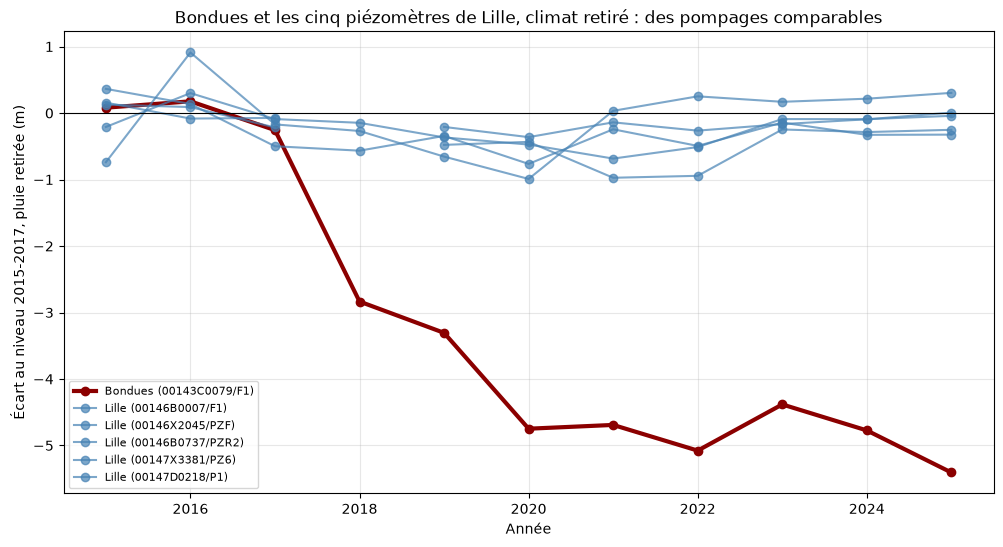

In [18]:
def fig_bondues_lille():
    """Trajectoires annuelles, climat retiré, de Bondues et des cinq piézomètres de Lille."""
    codes_duo = ["00143C0079/F1", "00146B0007/F1", "00146X2045/PZF", "00146B0737/PZR2", "00147X3381/PZ6", "00147D0218/P1"]
    codes_duo = [c for c in codes_duo if c in set(st["code_bss"])]   #Stations du Nord : ignorées si absentes
    plt.figure(figsize=(12, 6))
    for code in codes_duo:
        commune = st.loc[st["code_bss"] == code, "nom_commune"].iloc[0]
        style = {"color": "darkred", "linewidth": 3} if commune == "Bondues" else {"color": "steelblue", "alpha": 0.7}
        plt.plot(ecart_annuel.index, ecart_annuel[code], marker="o", label=f"{commune} ({code})", **style)
    plt.axhline(0, color="black", linewidth=0.8)
    plt.xlabel("Année")
    plt.ylabel("Écart au niveau 2015-2017, pluie retirée (m)")
    plt.title("Bondues et les cinq piézomètres de Lille, climat retiré : des pompages comparables")
    plt.legend(fontsize=8)
    plt.grid(True, alpha=0.3)
    plt.show()

if AFFICHER:
    fig_bondues_lille()

**Interprétation.** Volumes annuels moyens prélevés à moins de 5 km, en millions de m³, et tendance corrigée du climat.

- **Nieppe** (−36 cm/an) : quasiment aucun prélèvement (0,01 million de m³, uniquement pour l'irrigation). Sa baisse ne vient pas d'un pompage local, encore moins de l'industrie. C'est une nappe captive : sa tendance corrigée est à lire avec prudence.
- **Bondues** (−57 cm/an) : 5,8 millions de m³ par an, dont 36 % pour l'industrie. Le pompage y est important, mais l'eau potable y pèse davantage que l'industrie.
- **Lille** : une fois la pluie retirée, les cinq piézomètres sont presque stables, entre −4,6 et +2,7 cm/an (quatre en légère baisse), alors qu'ils sont entourés de 3,3 à 7,0 millions de m³ de prélèvements annuels. Deux d'entre eux ont plus de prélèvements totaux que Bondues, et deux autres plus de prélèvements industriels (jusqu'à 4,5 millions de m³, plus du double de Bondues).

À pompage comparable, voire supérieur, les nappes de Lille restent à moins de 1 m de leur niveau de 2015-2017, quand Bondues a perdu près de 5 m entre 2017 et 2020 sans remonter depuis : ce n'est pas la quantité d'eau prélevée qui fait la différence.

Limite : la BNPE n'indique pas dans quelle nappe pompe chaque forage. Les prélèvements proches de Bondues ne visent pas forcément la même nappe que le piézomètre.

In [19]:
moy = sout.groupby(["code_ouvrage", "code_usage"]).agg(volume=("volume", "mean"), geometry=("geometry", "first")).reset_index()
moy = gpd.GeoDataFrame(moy, geometry="geometry", crs=sout.crs)

st["vol_total_5km"] = st.geometry.apply(lambda g: moy.loc[moy.distance(g) <= 5000, "volume"].sum() / 1e6)
st["vol_ind_5km"] = st.geometry.apply(lambda g: moy.loc[(moy.distance(g) <= 5000) & (moy["code_usage"] == "IND"), "volume"].sum() / 1e6)

indicateurs = {
    "Nombre d'usines à 2 km": "usines_2km",
    "Nombre d'usines à 5 km": "usines_5km",
    "Nombre d'usines à 10 km": "usines_10km",
    "Volume total pompé à 5 km": "vol_total_5km",
    "Volume industriel pompé à 5 km": "vol_ind_5km"
}
#Corrélation avec la tendance corrigée du climat, et pour comparaison avec la tendance brute (avant retrait de la pluie)
tableau_corr = pd.DataFrame({
    "Indicateur de pression": list(indicateurs.keys()),
    "Spearman (tendance corrigée du climat)": [round(st["tendance_cm_an"].corr(st[c], method="spearman"), 2) for c in indicateurs.values()],
    "Spearman (tendance brute)": [round(st["pente_brute_cm_an"].corr(st[c], method="spearman"), 2) for c in indicateurs.values()]
})
print(tableau_corr.to_string(index=False))

        Indicateur de pression  Spearman (tendance corrigée du climat)  Spearman (tendance brute)
        Nombre d'usines à 2 km                                    0.13                       0.22
        Nombre d'usines à 5 km                                    0.01                       0.13
       Nombre d'usines à 10 km                                    0.10                       0.14
     Volume total pompé à 5 km                                    0.09                       0.12
Volume industriel pompé à 5 km                                    0.10                       0.25


**Interprétation.** Avec la tendance corrigée du climat, les cinq corrélations sont comprises entre 0,01 et 0,13 : proches de zéro et toutes positives. Que la pression soit mesurée par le nombre d'usines ou par les volumes réellement pompés, aucune relation négative n'apparaît : les nappes les plus exposées ne baissent pas davantage.

Avant le retrait de la pluie, les corrélations étaient un peu plus élevées (de 0,12 à 0,25). Retirer le climat les rapproche de zéro : le léger lien positif venait en partie de la pluie. Le reste peut tenir à la géologie, les gros pompages industriels se situant surtout au-dessus de la craie lilloise, qui se recharge vite. Une corrélation ne prouve pas une cause, mais l'absence de corrélation négative, avec cinq indicateurs et trois rayons, rend peu probable un effet important de l'industrie dans cet échantillon.

## 5.5 Conclusion de la partie 5

**Ce que change le retrait du climat.** Dans les niveaux bruts, la nappe typique du Nord semblait stable. Une fois la pluie retirée, 41 stations sur 45 baissent légèrement (médiane −4,6 cm/an) : les années humides de la fin de période masquaient cette baisse. Les plus fortes baisses se sont surtout produites entre 2017 et 2020.

**Cette baisse n'est pas liée à la pression industrielle.** Les corrélations de Spearman entre la tendance corrigée et la pression humaine sont proches de zéro (0,01 à 0,13) et jamais négatives, qu'on mesure la pression par le nombre d'usines ou par les volumes pompés, et quel que soit le rayon. Les médianes des groupes de pression diffèrent, mais les groupes se recouvrent presque entièrement et le groupe sans usine ne compte que 5 stations. Au cœur de la métropole lilloise, où les usines sont les plus denses, les nappes sont presque stables.

**L'industrie est un préleveur minoritaire.** Elle ne représente que 18 % des prélèvements souterrains du département, contre 80 % pour l'eau potable, et ses volumes sont restés stables entre 2015 et 2023.

**La nature de la nappe compte davantage.** Les ouvrages profonds baissent nettement plus (médiane −15,5 cm/an) que les superficiels (−3,5 cm/an), et l'écart entre géologies (environ 11 cm/an) dépasse largement celui entre groupes de pression (environ 5 cm/an). Bondues et Lille, entourés d'un nombre d'usines et de prélèvements comparables, l'illustrent : Bondues, nappe profonde dans le calcaire, a perdu près de 5 m entre 2017 et 2020 sans remonter, alors que les piézomètres superficiels de Lille, dans la craie, restent presque stables.

**Réponse à la problématique.** Dans le Nord, l'exposition locale aux activités industrielles n'amplifie pas de façon mesurable la baisse des nappes, même une fois l'effet de la pluie retiré. La vulnérabilité dépend surtout du type de nappe : les nappes profondes et calcaires, plus inertes, sont celles qui baissent le plus. L'implantation de nouvelles usines très consommatrices d'eau devrait donc tenir compte de la nappe dans laquelle elles pomperont.

### Limites

- Un échantillon réduit : 45 piézomètres bien suivis, avec de petits effectifs dans certains groupes (5 stations sans usine, 7 ouvrages profonds).
- La profondeur et la géologie se recoupent (6 des 7 ouvrages profonds sont calcaires) : on ne peut pas séparer leurs effets.
- Les plus fortes baisses sont des nappes captives, pour lesquelles le modèle climat est à lire avec prudence.
- Le modèle climat compte comme « climat » ce que les prélèvements ont de saisonnier ou de lié à la sécheresse : la tendance corrigée sous-estime probablement l'effet humain.
- Une tendance ne dit pas si la baisse est régulière : celle de Bondues est concentrée sur 2017-2020.
- Des corrélations, qui ne prouvent pas une causalité.

### Perspective

Il serait intéressant de reproduire cette analyse dans une région plus sèche, ou dont l'industrie est plus consommatrice d'eau, pour voir si les conclusions restent les mêmes.

In [20]:
#Marqueur : cette étape est faite, les notebooks qui en dépendent ne la relanceront pas dans ce noyau
ETAPE_05 = True